In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

font = {"size": 26}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 5
plt.rcParams["legend.fontsize"] = 20

# The Discrete Hankel Transform

In [2]:
def DHTarrays(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    r = R * Zeroes[:N] / Zeroes[N - 1]
    k = Zeroes[:N] / R
    return np.array([r, k])

def DHTtransformMatrix(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    alpha = Zeroes[:N]
    kR = alpha[N - 1]
    kmax = kR / R
    T = (
        jv(ell, np.outer(alpha, alpha) / kR)
        / np.outer(abs(jv(ell + 1, alpha)), abs(jv(ell + 1, alpha)))
        / kR
    )
    # print(T)
    A = abs(jv(ell + 1, alpha))
    T_R2K = 4.0 * np.pi * (R / kmax) * T * A[:, None] / A[None, :]
    T_K2R = (1 / np.pi) * (kmax / R) * T * A[:, None] / A[None, :]

    return T_R2K, T_K2R

# Propagation

Propagates incident beam `phi_I` over `z` after reflecting from the mirror `zm`using DHT

In [3]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, z, zm, wavelength):
    k0 = 2 * np.pi / wavelength
    phi_R0 = phi_I * np.exp(-2j * k0 * zm) #reflected profile from mirror

    # Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ phi_R0
    # Propagate phi_R0 over z through multiplying phi_R0 by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)

    return fT

# Sagitta Function
$s_f(r)=\frac{R^2}{4L}\ln\left[1+\frac{L}{f_0}\left(\frac{r}{R}\right)^2\right]$


In [4]:
def create_axiparabola(r,R,L,f0):
    # sag = R**2/(4*L)*np.log(1+L/f0*(r/R)**2)
    sag=r**2/(4*f0)*(1-L/(2*f0)*(r/R)**2)
    return sag

In [5]:
# Parameters from "Programmable-trajectory ultrafast flying focus pulses" paper
f = 0.5   # focal length of lens
R=0.05    # maximum radius of axiparabola
wl=1e-6 # wavelength
L=0    # length of focal range

ell = 0   # order of Bessel J function
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
nr=1000   # number of points in r

In [6]:
# Hankel
[r, k] = DHTarrays(nr, R, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, R, ell)

# Initial beam $\phi_I$

In [ ]:
phi_I = np.exp(-((r / (0.5*R)) ** 8))
# plt.plot(r, phi_I, label="Initial beam")

zm_t=create_axiparabola(r,R,L,f)
# plt.plot(r,zm_t, label="Axiparabola")
# plt.xlabel("r (m)")
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

# plt.show()

# Reproducing figure in paper

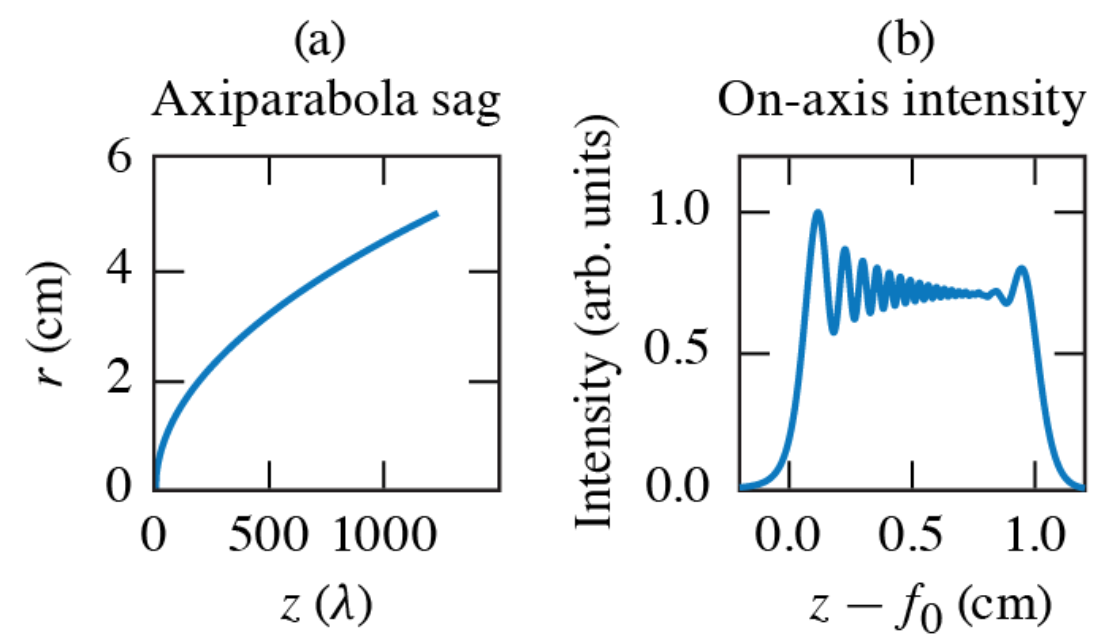

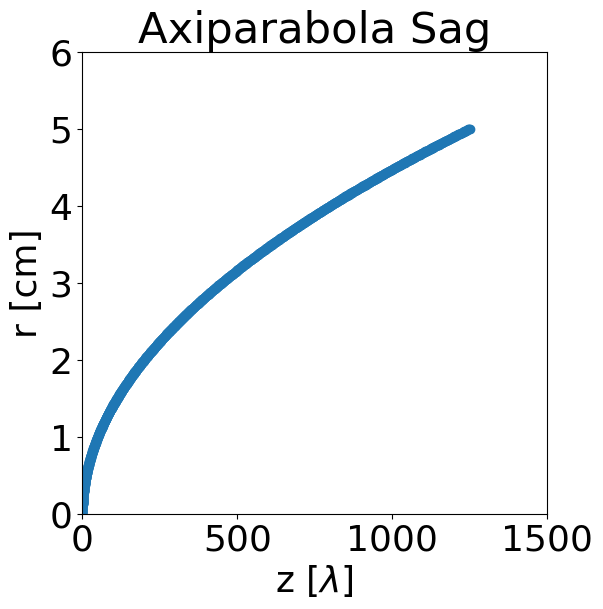

In [8]:
plt.figure(figsize=(6,6))
plt.scatter(zm_t/wl,r*100)
plt.xlim([0,1500])
plt.ylim([0,6])
plt.xlabel(r"z [$\lambda$]")
plt.ylabel("r [cm]")
plt.title('Axiparabola Sag')
plt.show()

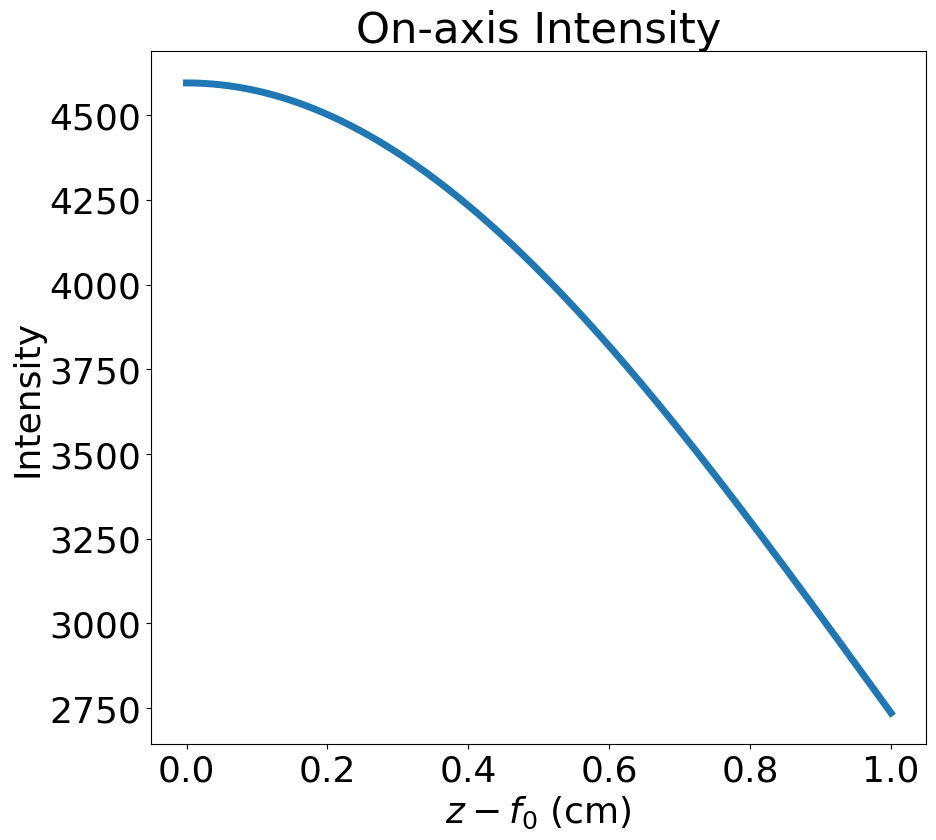

In [9]:
zF = np.linspace(f, f+0.01, 1000)
plt.figure(figsize=(10,9))
ftf_t = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm_t, wl)  # Target profile defined using target mirror
plt.plot((zF-f)*100, np.abs(ftf_t[0,:])**2, label="Target Mirror")
plt.xlabel(r"$z-f_0$ (cm)")
plt.ylabel("Intensity")
plt.title('On-axis Intensity')
plt.show()

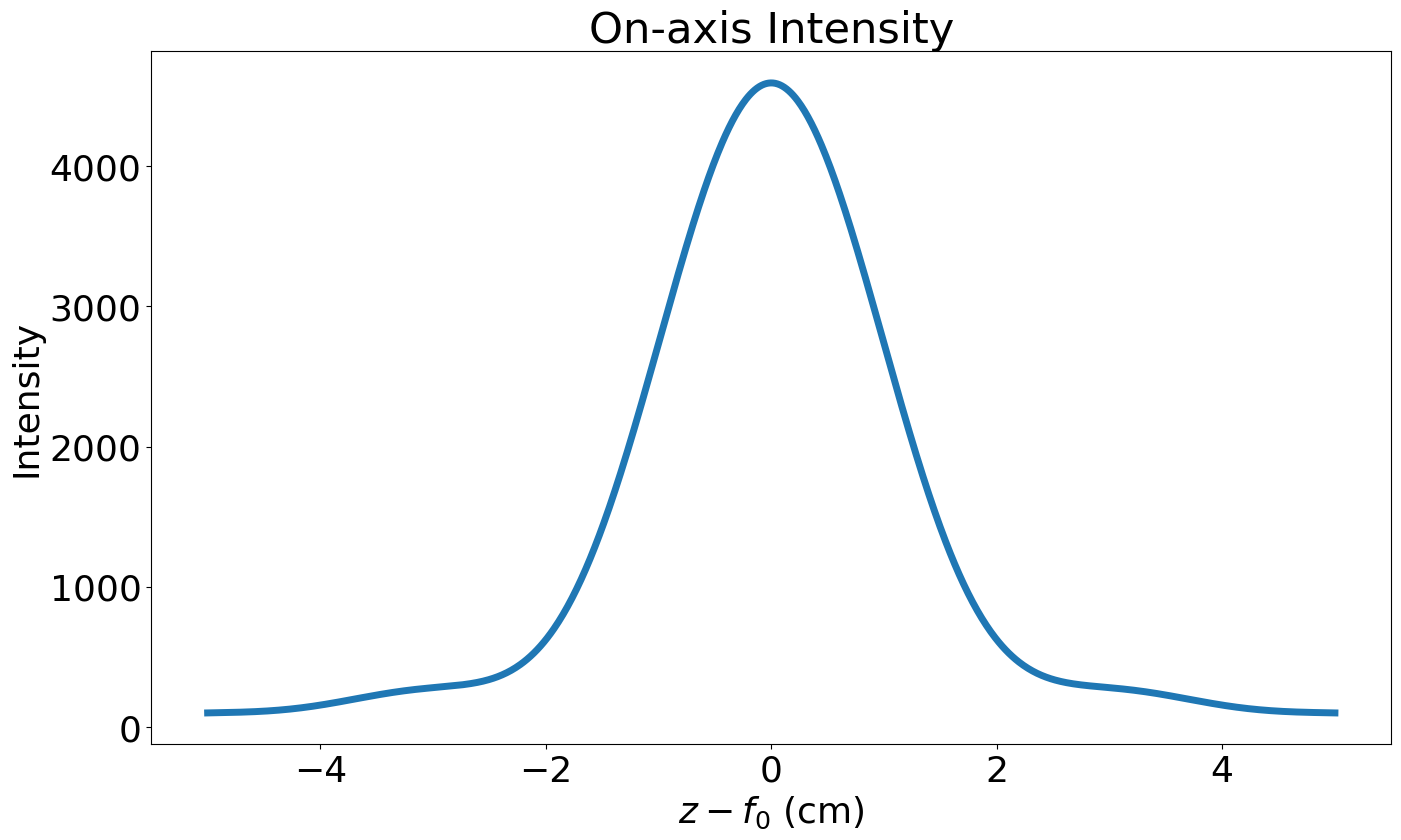

In [10]:
zF = np.linspace(f-0.05, f+0.05, 1000)

ftf_t = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm_t, wl)  # Target profile defined using target mirror
plt.plot((zF-f)*100, np.abs(ftf_t[0,:])**2, label="Target Mirror")
plt.xlabel(r"$z-f_0$ (cm)")
plt.ylabel("Intensity")
plt.title('On-axis Intensity')
plt.show()


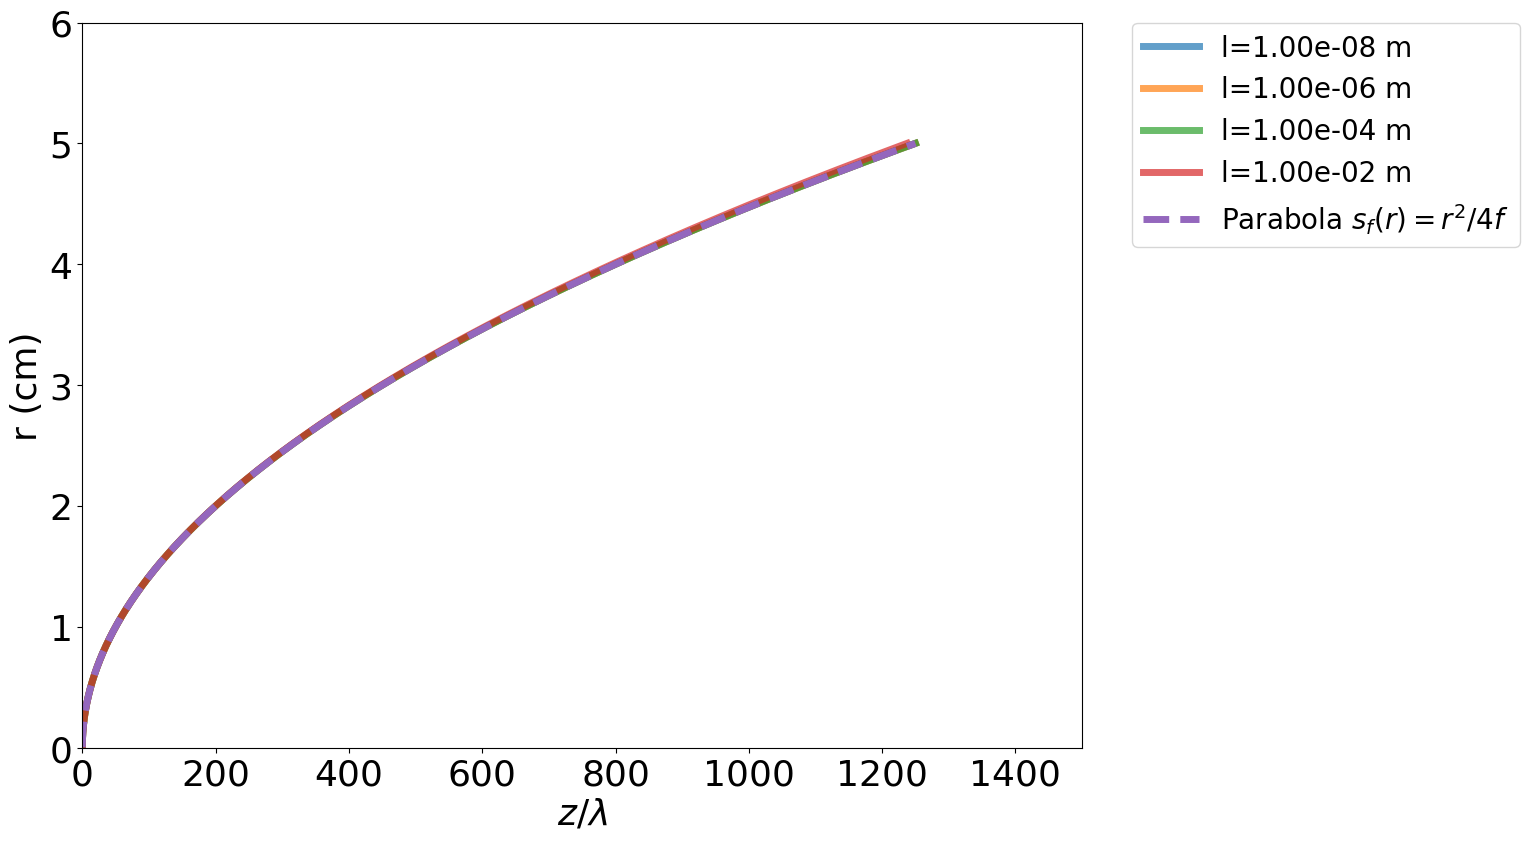

In [11]:
lengths=[1e-8,1e-6,1e-4,1e-2]
mirrors=[]
for l in lengths:
  z_m=create_axiparabola(r,R,l,f)
  mirrors.append(z_m)
  plt.plot(z_m/wl, r*100, label='l=%.2e m' % l, alpha=0.7)

plt.plot(r**2/(4*f)/wl, r*100, label=r'Parabola $s_f(r)=r^2/4f$', linestyle='--')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.xlim([0,1500])
plt.ylim([0,6])

plt.ylabel("r (cm)")
plt.xlabel(r'$z/\lambda$')
plt.tight_layout()
plt.show()

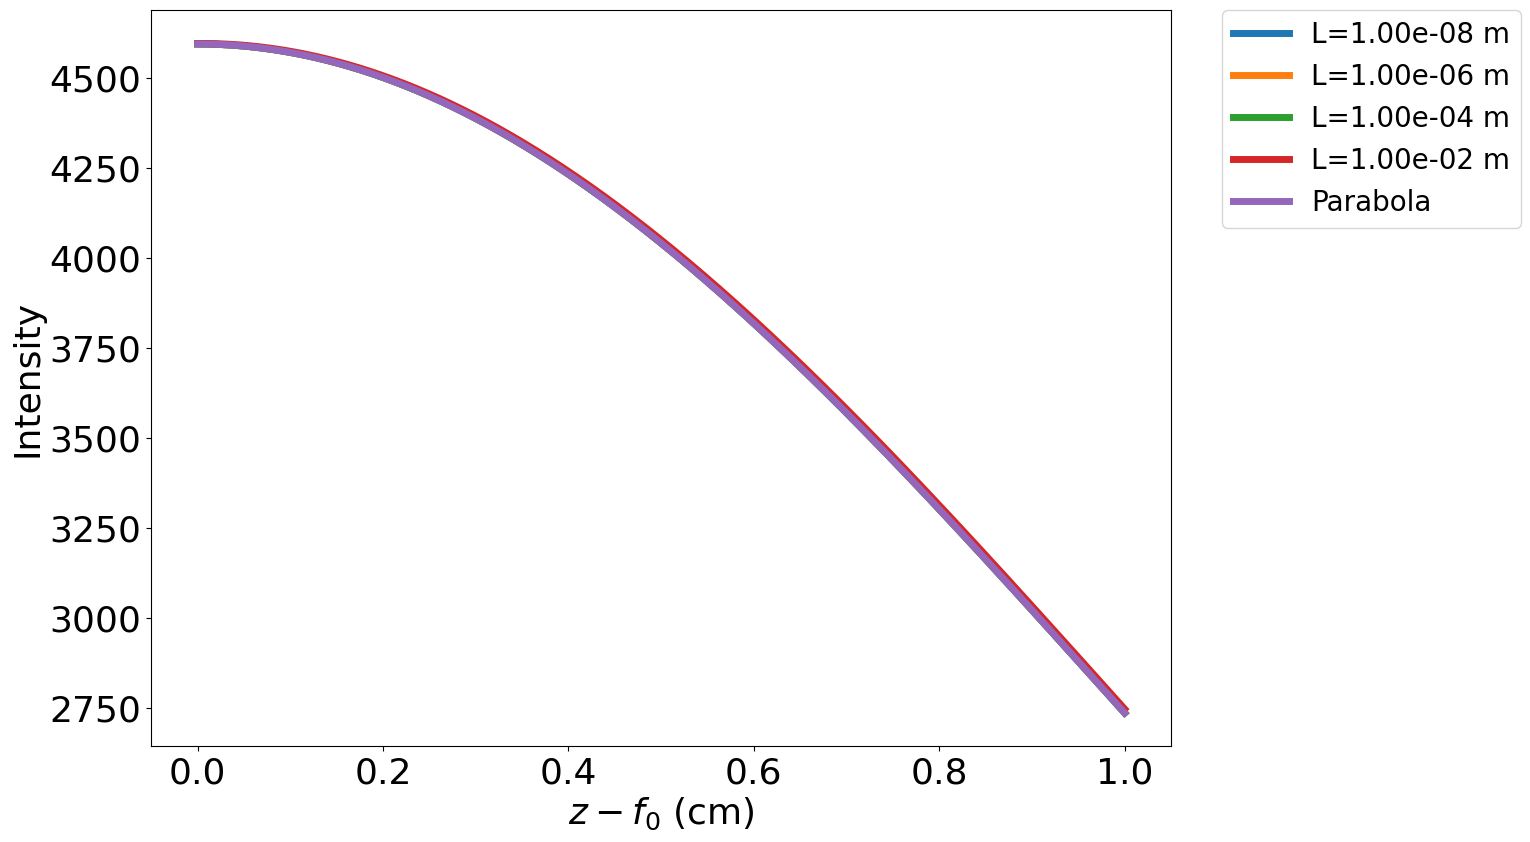

In [12]:
zF = np.linspace(f, f+0.01, 1000)

for l,m in zip(lengths,mirrors):
  ftf_t = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, m, wl)  # Target profile defined using target mirror
  plt.plot((zF-f)*100, np.abs(ftf_t[0,:])**2, label='L=%.2e m'%l)

ftf_parabola = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, r**2/(4*f), wl)  # Target profile defined using target mirror
plt.plot((zF-f)*100, np.abs(ftf_parabola[0,:])**2, label="Parabola")
plt.xlabel(r"$z-f_0$ (cm)")
plt.ylabel("Intensity")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()

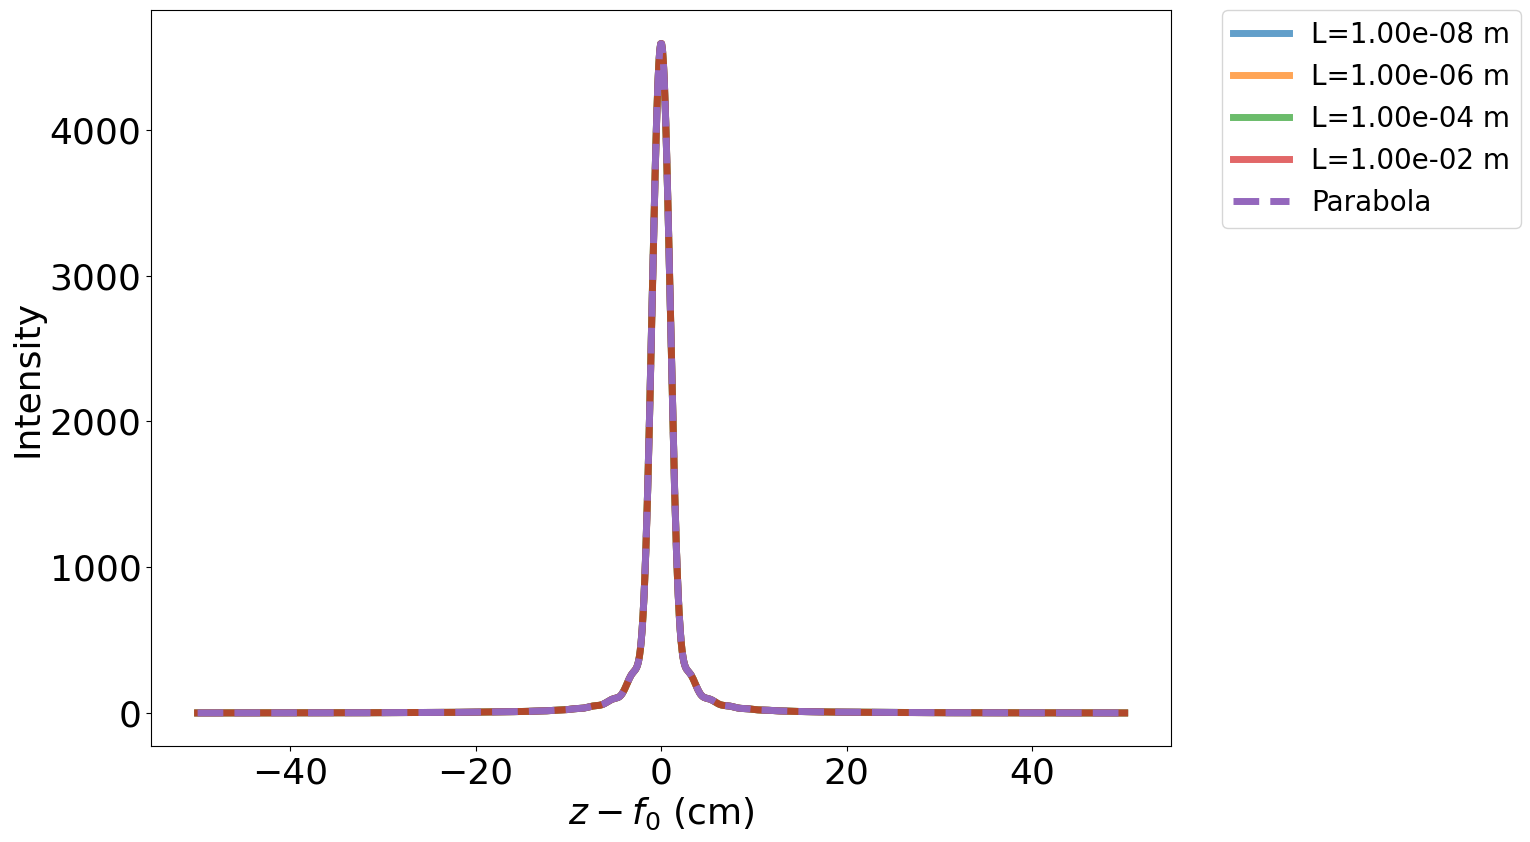

In [13]:
zF = np.linspace(0, f+0.5, 1000)

for l,m in zip(lengths,mirrors):
  ftf_t = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, m, wl)  # Target profile defined using target mirror
  plt.plot((zF-f)*100, np.abs(ftf_t[0,:])**2, label='L=%.2e m'%l, alpha=0.7)
# plt.axvline(x=zm_t[-1], coor="r", linestyle="--", label="Target Mirror")
ftf_parabola = forward_propagation(k, phi_I, T_R2K, T_K2R, zF, r**2/(4*f), wl)  # Target profile defined using target mirror
plt.plot((zF-f)*100, np.abs(ftf_parabola[0,:])**2, label="Parabola", linestyle='--')

plt.xlabel(r"$z-f_0$ (cm)")
plt.ylabel("Intensity")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()